# Project 1 -- 3D CNN on structural MRI

- Class: CSE 6389
- Name: John (chenxi) Song
- ID: 1002306479



## 1. Data Description

- training: 20 ---> 10 in patient, 10 in health
- testing: 10----> 5 in patient, 5 in health
- (141, 199, 190) array stored as .nii.gz

### 1. Example of health data

##### 1. Mount to Google drive for data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


###### 2. Showing one data

In [7]:
example_health = '/content/drive/MyDrive/6389_data/Project/Project1/Assignment1/Training/health/T1_bet_2_0413_sub01.nii.gz'

In [2]:
import nibabel as nib
import numpy as np

In [9]:
health_img = nib.load(example_health)
health_data = health_img.get_fdata().astype(np.float32)

print("Example shape:", health_data.shape)
print("Example dtype:", health_data.dtype)
print("Coordination:", nib.aff2axcodes(health_img.affine))

Example shape: (141, 199, 190)
Example dtype: float32
Coordination: ('R', 'A', 'S')


### 2. Visulization

In [3]:
import matplotlib.pyplot as plt

In [11]:
print("min:", health_data.min())
print("max:", health_data.max())
print("mean:", health_data.mean())

min: 0.0
max: 928.1625
mean: 50.063004


In [12]:
x_mid = health_data.shape[0] // 2
y_mid = health_data.shape[1] // 2
z_mid = health_data.shape[2] // 2

slice_axis0 = health_data[x_mid, :, :]
slice_axis1 = health_data[:, y_mid, :]
slice_axis2 = health_data[:, :, z_mid]

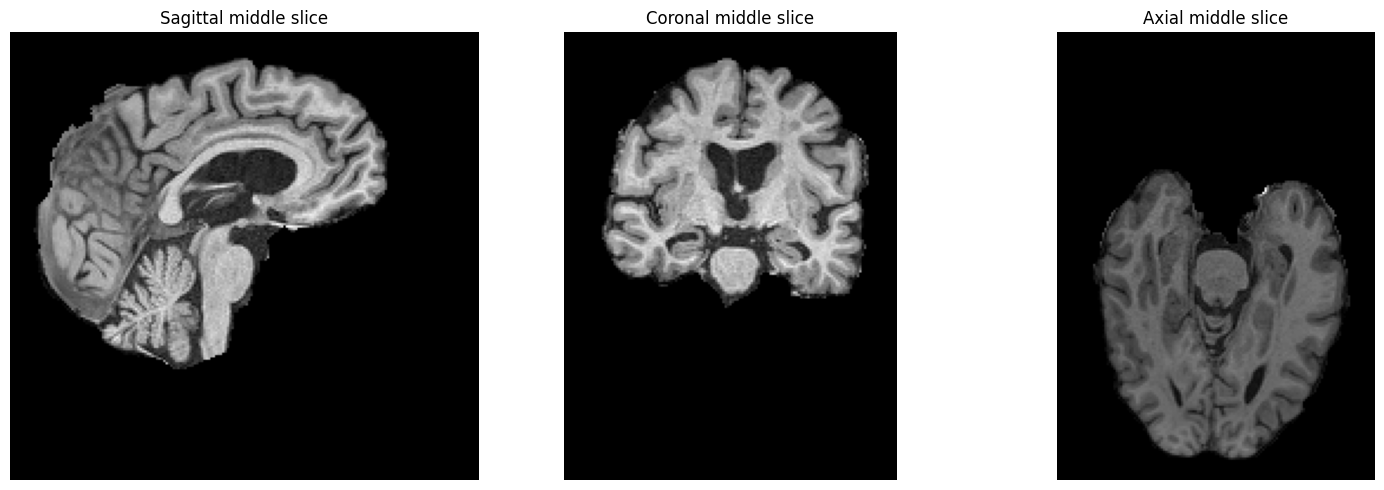

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(slice_axis0.T, cmap='gray', origin='lower')
axes[0].set_title('Sagittal middle slice')
axes[0].axis('off')

axes[1].imshow(slice_axis1.T, cmap='gray', origin='lower')
axes[1].set_title('Coronal middle slice')
axes[1].axis('off')

axes[2].imshow(slice_axis2.T, cmap='gray', origin='lower')
axes[2].set_title('Axial middle slice')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 2. Data Preprocessing (EDA Analysis)

### 2.1 Data Loading and Basic Preprocessing

Each MRI scan is stored as a 3D NIfTI volume. The class label is determined by the folder containing the scan:

- `health` → label 0
- `patient` → label 1

Each volume is loaded with `nibabel`, converted to `float32`, and kept in its original 3D form for later CNN training.

The background voxels are zero because the images are skull-stripped. These zero-valued voxels are kept in the 3D volume for CNN input, but they will be excluded when calculating brain-intensity statistics.



In [4]:
from pathlib import Path
import numpy as np
import nibabel as nib

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
DATA_ROOT = Path("/content/drive/MyDrive/6389_data/Project/Project1/Assignment1")

In [6]:
def load_project1(split="Training"):
    if split not in ("Training", "Testing"):
        raise ValueError("split must be 'Training' or 'Testing'")

    dataset = []  # dataset to store

    for class_name, label in [("health", 0),("patient", 1)]:
        folder = DATA_ROOT / split / class_name   # get dir from data

        for file_path in folder.iterdir():
            if file_path.name.endswith(".nii.gz"):
                img = nib.load(str(file_path))  # get brain meta info
                data = img.get_fdata().astype(np.float32)   # get brain 3D array [R, A, S]

                dataset.append({
                    "subject": file_path.name,
                    "class": class_name,
                    "label": label,
                    "data": data
                })

    return dataset

In [7]:
train_data = load_project1("Training")
test_data = load_project1("Testing")

In [8]:
print("Training subjects:", len(train_data))
print("Testing subjects:", len(test_data))

print("\nExample subject:")
print("File:", train_data[0]["subject"])
print("Class:", train_data[0]["class"])
print("Label:", train_data[0]["label"])
print("Shape:", train_data[0]["data"].shape)
print("dtype:", train_data[0]["data"].dtype)

Training subjects: 20
Testing subjects: 10

Example subject:
File: T1_bet_2_0413_sub10.nii.gz
Class: health
Label: 0
Shape: (141, 199, 190)
dtype: float32


### 2.2 Descriptive Statistics of Nonzero Brain Voxels

Because the MRI volumes are skull-stripped, zero-valued voxels mainly represent background rather than brain tissue.

Therefore, descriptive intensity statistics are calculated using only nonzero voxels:

$$
X_{\text{brain}} = X[X > 0]
$$

For each subject, we calculate:

- minimum and maximum intensity
- mean intensity
- standard deviation
- 25th percentile
- median
- 75th percentile
- interquartile range (IQR)
- fraction of nonzero voxels

These statistics provide a subject-level summary of the MRI intensity distributions before CNN modeling.

In [31]:
import numpy as np
import pandas as pd

def calculate_stats_project1(dataset):
    results = []

    for subject in dataset:
        data = subject["data"]
        brain = data[data>0] ## get rid of background (0-voxels).... to 1 D array for stats convent...

        q25, q50, q75 = np.percentile(brain, [25, 50, 75])

        results.append({
            "subject":subject["subject"],
            "class":subject["class"],
            "max":brain.max(),
            "min":brain.min(),
            "mean": brain.mean(),
            "std": brain.std(),
            "q25": q25,
            "q50": q50,
            "q75": q75,
            "iqr": q75 - q25,
            "non_zero_frac": len(brain) / data.size,
        })


    return pd.DataFrame(results)

In [20]:
train_stats = calculate_stats_project1(train_data)
test_stats = calculate_stats_project1(test_data)

In [21]:
train_stats

,subject,class,max,min,mean,std,q25,q50,q75,iqr,non_zero_frac
0,T1_bet_2_0413_sub10.nii.gz,health,349.262085,0.880378,121.621445,47.007610,84.519991,128.752037,164.150410,79.630419,0.211270
1,T1_bet_2_0413_sub01.nii.gz,health,928.162476,0.789434,247.976257,97.785568,185.086910,269.084198,327.401512,142.314602,0.201886
2,T1_bet_2_0413_sub08.nii.gz,health,1103.568726,0.890236,298.522827,109.156342,219.289997,320.330276,390.386230,171.096233,0.210910
3,T1_bet_2_0413_sub07.nii.gz,health,1037.181396,0.884696,279.167114,95.307190,224.699093,291.787491,358.254028,133.554935,0.219791
4,T1_bet_2_0413_sub06.nii.gz,health,1081.803223,0.838442,294.239349,110.131981,218.113537,317.495346,386.126152,168.012615,0.215399
5,T1_bet_2_0413_sub04.nii.gz,health,1087.729126,0.927153,306.994476,118.609009,235.334862,319.908447,410.789886,175.455025,0.217241
6,T1_bet_2_0413_sub02.nii.gz,health,920.676697,0.941791,306.566498,121.673431,205.395981,333.967957,409.891617,204.495636,0.213418
7,T1_bet_2_0413_sub03.nii.gz,health,868.678772,0.918917,276.995270,94.818909,214.701424,298.701111,353.268112,138.566689,0.215292
8,T1_bet_2_0413_sub09.nii.gz,health,437.382385,0.895947,126.673737,45.316189,94.618858,138.975266,162.555824,67.936966,0.212597
9,T1_bet_2_0413_sub05.nii.gz,health,786.128601,0.902036,272.188446,101.634232,214.300240,282.569702,360.988754,146.688515,0.218852


In [22]:
def plot_subject_box_summaries(train_stats):
    df = train_stats.copy()

    # extract subject number for ordering
    df["subject_id"] = (
        df["subject"]
        .str.extract(r"sub(\d+)")
        .astype(int)
    )

    df = df.sort_values(["class", "subject_id"])

    health = df[df["class"] == "health"]
    patient = df[df["class"] == "patient"]

    fig, ax = plt.subplots(figsize=(15, 6))

    # x positions
    x_health = np.arange(len(health))
    x_patient = np.arange(len(patient)) + len(health) + 2

    def draw_group(group, x_positions, color):
        for x, (_, row) in zip(x_positions, group.iterrows()):

            # whisker: min -> max
            ax.vlines(
                x,
                row["min"],
                row["max"],
                color=color,
                linewidth=1.5,
                alpha=0.7
            )

            # box: q25 -> q75
            ax.add_patch(
                plt.Rectangle(
                    (x - 0.28, row["q25"]),
                    0.56,
                    row["q75"] - row["q25"],
                    facecolor=color,
                    edgecolor=color,
                    alpha=0.35,
                    linewidth=1.5
                )
            )

            # median
            ax.hlines(
                row["q50"],
                x - 0.28,
                x + 0.28,
                color=color,
                linewidth=3
            )

            # mean
            ax.scatter(
                x,
                row["mean"],
                color="black",
                s=28,
                zorder=3
            )

    draw_group(health, x_health, "steelblue")
    draw_group(patient, x_patient, "tomato")

    # labels
    x_all = np.concatenate([x_health, x_patient])
    labels = (
        [f"H{n:02d}" for n in health["subject_id"]] +
        [f"P{n:02d}" for n in patient["subject_id"]]
    )

    ax.set_xticks(x_all)
    ax.set_xticklabels(labels, rotation=45)

    ax.set_ylabel("Nonzero voxel intensity")
    ax.set_xlabel("Training subjects")
    ax.set_title("Per-Subject Brain Intensity Distribution Summary")

    ax.grid(axis="y", alpha=0.2)

    # class labels
    ax.text(
        x_health.mean(),
        ax.get_ylim()[1] * 0.98,
        "Health",
        ha="center",
        color="steelblue",
        fontweight="bold"
    )

    ax.text(
        x_patient.mean(),
        ax.get_ylim()[1] * 0.98,
        "Patient",
        ha="center",
        color="tomato",
        fontweight="bold"
    )

    # average mean intensity across health subjects
    health_avg = health["mean"].mean()

    ax.hlines(
    health_avg,
    xmin=x_health.min() - 0.4,
    xmax=x_health.max() + 0.4,
    color="steelblue",
    linestyle="--",
    linewidth=2,
    label=f"Health average = {health_avg:.1f}"
)

# average mean intensity across patient subjects
    patient_avg = patient["mean"].mean()

    ax.hlines(
    patient_avg,
    xmin=x_patient.min() - 0.4,
    xmax=x_patient.max() + 0.4,
    color="tomato",
    linestyle="--",
    linewidth=2,
    label=f"Patient average = {patient_avg:.1f}"
)

    ax.legend(frameon=False)

    plt.tight_layout()
    plt.show()

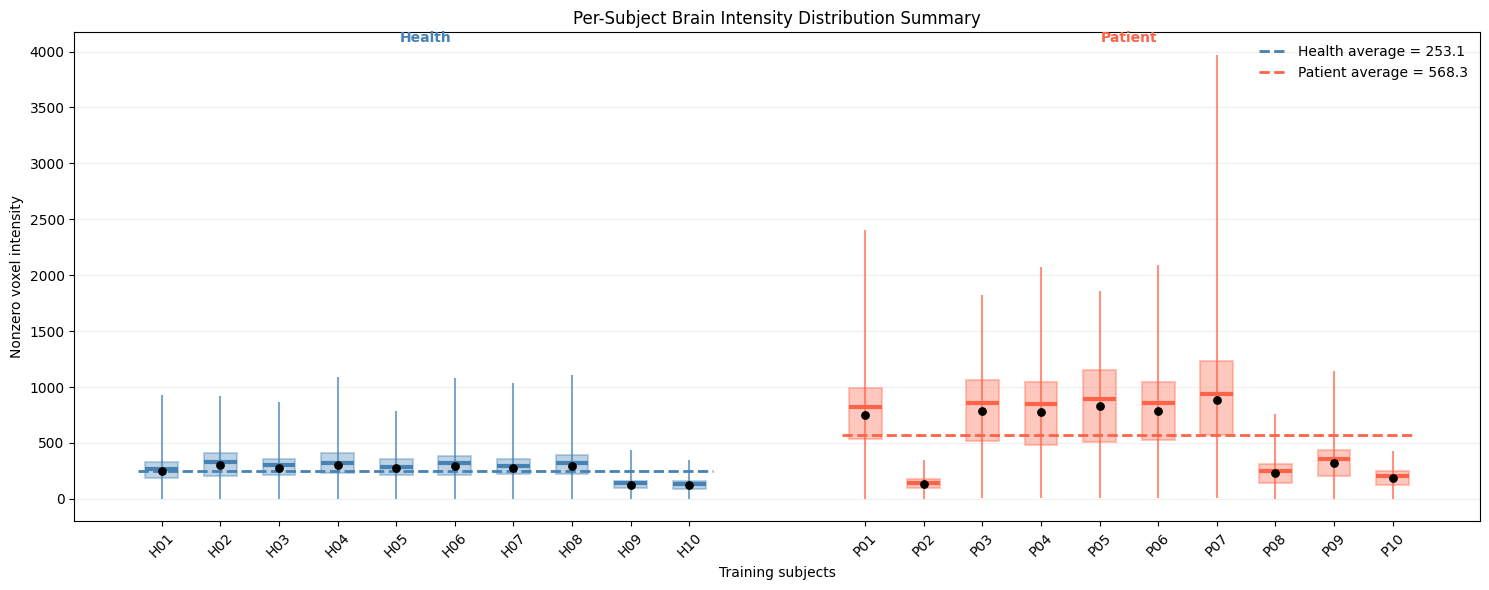

In [23]:
plot_subject_box_summaries(train_stats)

In [24]:
def best_threshold(values, labels):
    """
    Fit the best 1D threshold on training data only.
    Rule: value > threshold -> patient (label 1)
    """
    v = np.asarray(values, dtype=float)
    y = np.asarray(labels, dtype=int)

    unique_vals = np.unique(v)
    candidates = np.concatenate([
        [unique_vals[0] - 1.0],
        0.5 * (unique_vals[:-1] + unique_vals[1:]),
        [unique_vals[-1] + 1.0]
    ])

    accs = np.array([
        np.mean((v > t).astype(int) == y)
        for t in candidates
    ])

    i = np.argmax(accs)
    return float(candidates[i]), float(accs[i])

def plot_mean_threshold(train_stats, test_stats):
    # copy and add split column
    train_df = train_stats.copy()
    test_df = test_stats.copy()

    train_df["split"] = "Training"
    test_df["split"] = "Testing"

    all_df = pd.concat([train_df, test_df], ignore_index=True)

    # numeric labels
    train_labels = (train_df["class"] == "patient").astype(int).values
    test_labels = (test_df["class"] == "patient").astype(int).values

    # fit threshold ONLY on training means
    threshold, train_acc = best_threshold(train_df["mean"].values, train_labels)

    # evaluate on test
    test_pred = (test_df["mean"].values > threshold).astype(int)
    test_acc = np.mean(test_pred == test_labels)

    # plotting
    fig, ax = plt.subplots(figsize=(9, 6))

    colors = {"health": "steelblue", "patient": "tomato"}

    # plot training
    for cls in ["health", "patient"]:
        group = train_df[train_df["class"] == cls]
        x = np.zeros(len(group)) + np.linspace(-0.12, 0.12, len(group))

        ax.scatter(
            x, group["mean"],
            color=colors[cls],
            s=80,
            marker="o",
            edgecolor="black",
            linewidth=0.5,
            alpha=0.85,
            label=f"{cls} Training"
        )

    # plot testing
    for cls in ["health", "patient"]:
        group = test_df[test_df["class"] == cls]
        x = np.ones(len(group)) + np.linspace(-0.12, 0.12, len(group))

        ax.scatter(
            x, group["mean"],
            color=colors[cls],
            s=120,
            marker="^",
            edgecolor="black",
            linewidth=0.5,
            alpha=0.90,
            label=f"{cls} Testing"
        )

    # threshold line
    ax.axhline(
        threshold,
        color="black",
        linestyle="--",
        linewidth=1.5
    )

    ax.text(
        0.5, threshold + 15,
        f"training-fitted threshold = {threshold:.1f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Training", "Testing"])
    ax.set_xlim(-0.35, 1.35)
    ax.set_ylabel("Mean intensity over nonzero voxels")
    ax.set_title(
        f"One Scalar per Brain: Train {train_acc:.0%}, Test {test_acc:.0%}"
    )

    ax.grid(axis="y", alpha=0.2)

    # remove duplicate legend entries
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))
    ax.legend(unique.values(), unique.keys(), frameon=False, fontsize=9)

    plt.tight_layout()
    plt.show()

    print(f"Best threshold (fit on training): {threshold:.1f}")
    print(f"Training accuracy: {train_acc:.0%}")
    print(f"Testing accuracy: {test_acc:.0%}")

    return threshold, train_acc, test_acc

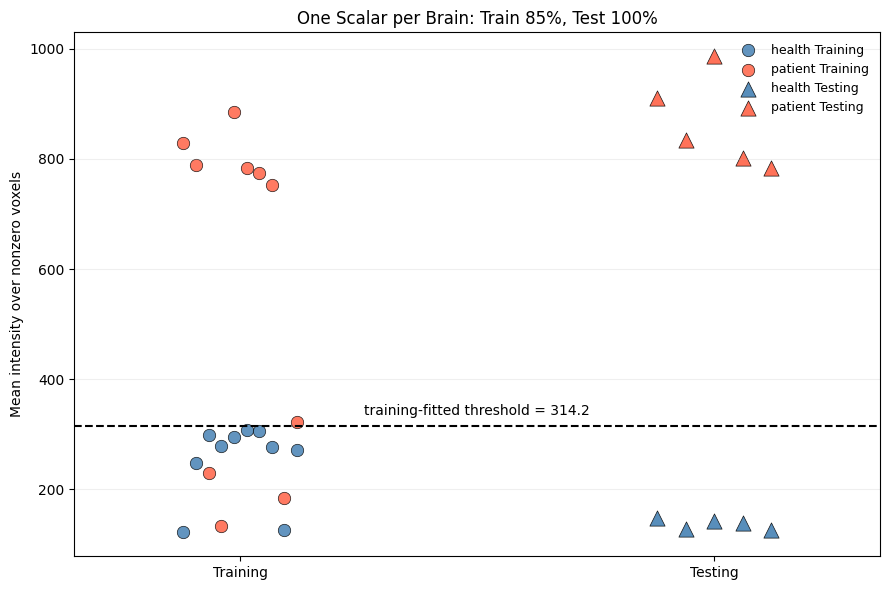

Best threshold (fit on training): 314.2
Training accuracy: 85%
Testing accuracy: 100%


In [25]:
threshold, train_acc, test_acc = plot_mean_threshold(train_stats, test_stats)

The boxplot shows a clear separation in global intensity distributions between the health and patient groups. Using a simple threshold based on subject-level mean nonzero intensity, the provided test set can be classified with 100% accuracy. This indicates that global intensity scale alone contains very strong class-discriminative information in this dataset. However, this result should be interpreted cautiously: the separation may reflect differences in image acquisition or preprocessing rather than disease-related anatomical patterns. Therefore, per-volume intensity normalization is necessary to reduce this potential shortcut before comparing CNN performance.

### 2.4 Per-Volume Intensity Normalization

The exploratory analysis showed that raw MRI intensity scale differs substantially across subjects and is strongly associated with the class label. Because absolute MRI intensity values are not inherently standardized across scans, a CNN trained directly on the raw data may learn this global intensity difference as a shortcut instead of learning disease-related spatial or anatomical patterns.

To reduce this effect, each MRI volume is normalized independently using the median intensity of its nonzero brain voxels:

$$
X_{\text{norm}} =
\frac{X}{\operatorname{median}(X[X>0])}
$$

Only nonzero voxels are used to calculate the median so that the zero-valued background does not influence the normalization factor. The entire 3D volume is then divided by this scalar value, so the background remains zero and the spatial structure of the MRI is unchanged.



In [12]:
def normalize_volume_by_median(data):
    brain = data[data > 0]
    median = np.median(brain)

    return data / median


def normalize_dataset(dataset):
    normalized_dataset = []

    for subject in dataset:
        normalized_data = normalize_volume_by_median(subject["data"])

        normalized_dataset.append({
            "subject": subject["subject"],
            "class": subject["class"],
            "label": subject["label"],
            "data": normalized_data
        })

    return normalized_dataset

In [10]:
train_data_norm = normalize_dataset(train_data)
test_data_norm = normalize_dataset(test_data)

In [32]:
train_stats_norm = calculate_stats_project1(train_data_norm)
test_stats_norm = calculate_stats_project1(test_data_norm)

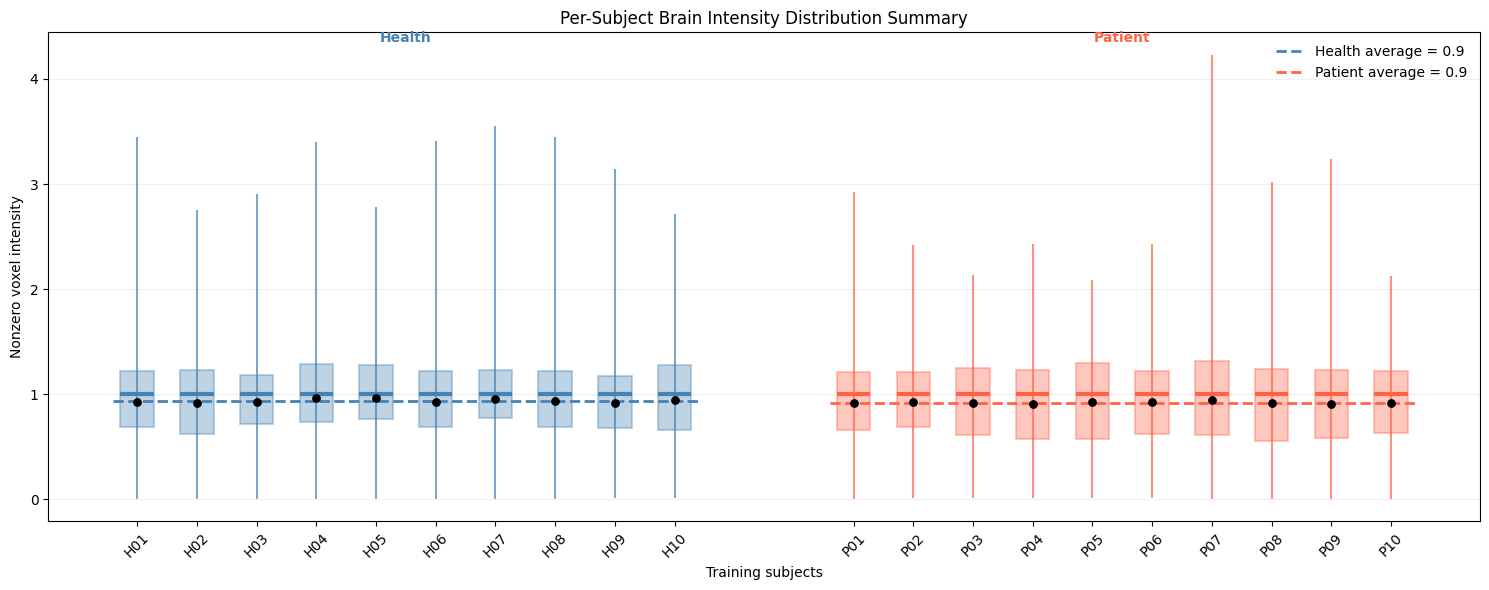

In [29]:
plot_subject_box_summaries(train_stats_norm)

After normalization, the median nonzero brain intensity of every subject is approximately 1.0. This removes differences caused primarily by multiplicative intensity scaling while preserving the relative intensity relationships between voxels and the original 3D spatial organization.

The purpose of this preprocessing step is not to make all subjects identical, but to reduce global intensity-scale variation so that the CNN is less able to rely on absolute brightness as a class-discriminative shortcut.

Raw data retain the strong intensity-scale signal, while normalized data reduce it. The next experiment therefore trains the same CNN on both datasets and compares their classification performance.

## 3. Input Data Preparation & Modeling

- Raw MRI data
- Normalized MRI data
- CNN network structure

In [13]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
import gc

### 3.1 Data Loader

In [14]:
class MRIDataset(Dataset):

    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        subject = self.dataset[idx]

        volume = subject["data"]
        label = subject["label"]

        # (141,199,190) -> (1,141,199,190)  with gray color.
        volume = torch.from_numpy(volume).float().unsqueeze(0)

        label = torch.tensor(label, dtype=torch.long)

        return volume, label



def make_loaders(train_dataset, test_dataset, seed, batch_size=2):

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        MRIDataset(train_dataset),
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    test_loader = DataLoader(
        MRIDataset(test_dataset),
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, test_loader

### 3.2 Modeling

```
Input MRI
→ Conv3D + ReLU + MaxPool
→ Conv3D + ReLU + MaxPool
→ Conv3D + ReLU + MaxPool
→ Conv3D + ReLU + MaxPool
→ Conv3D + ReLU + MaxPool
→ Flatten
→ Fully Connected
→ Fully Connected
→ Output


1 × 141 × 199 × 190
→ 8 × 70 × 99 × 95
→ 16 × 35 × 49 × 47
→ 32 × 17 × 24 × 23
→ 64 × 8 × 12 × 11
→ 128 × 4 × 6 × 5
→ 15,360 features
→ 1300
→ 50
→ 2 classes
```

In [15]:
class MRI3DCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv3d(1, 8, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv3d(8, 16,kernel_size=3,stride=1,padding=1)
        self.conv3 = nn.Conv3d(16, 32, kernel_size=3,stride=1,padding=1)
        self.conv4 = nn.Conv3d(32, 64,kernel_size=3,stride=1,padding=1)
        self.conv5 = nn.Conv3d(64, 128,kernel_size=3,stride=1,padding=1)

        self.pool = nn.MaxPool3d(kernel_size=2,stride=2)

        self.fc1 = nn.Linear(128 * 4 * 6 * 5,1300)
        self.fc2 = nn.Linear(1300,50)
        self.fc3 = nn.Linear(50,2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.pool(F.relu(self.conv4(x)))
        x = self.pool(F.relu(self.conv5(x)))

        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        # raw logits
        x = self.fc3(x)

        return x


### 3.3 Design Choices and Hyperparameters

The CNN was designed to progressively extract higher-level 3D spatial features while reducing the spatial dimensions of the MRI volume.

A convolution kernel size of $(3 \times 3 \times 3)$ was used throughout the network. Small kernels allow the model to learn local 3D patterns while keeping the number of parameters manageable. A stride of 1 and padding of 1 were used in the convolutional layers so that the spatial dimensions were preserved before pooling.

After each convolutional layer, a ReLU activation function was applied to introduce nonlinearity. Max pooling with a $(2 \times 2 \times 2)$ kernel and stride 2 was then used to reduce the spatial dimensions by approximately half. This gradually compresses the MRI volume while increasing the number of learned feature maps.

The number of convolutional channels was increased as:

$$
8 \rightarrow 16 \rightarrow 32 \rightarrow 64 \rightarrow 128
$$

As the spatial resolution decreases, the larger number of channels allows the network to represent a richer set of learned features.

After the final convolution and pooling stage, the feature maps were flattened and passed through fully connected layers of 1300 and 50 neurons. The final layer contains two output neurons corresponding to the two classes: health and patient.

The same CNN architecture was used for both the raw and normalized MRI experiments. This controlled design ensures that the main experimental difference is the intensity preprocessing method rather than changes in model architecture.

## 4. Training Model

### 4.1 Training Configuration

The CNN was trained as a binary classification model using the provided training set. Each subject was treated as one training sample consisting of a complete 3D MRI volume and one class label.

The model was trained using the Adam optimizer and cross-entropy loss. Cross-entropy loss is appropriate because the network produces two output logits corresponding to the health and patient classes.

The following training hyperparameters were used:

| Hyperparameter | Value |
|---|---:|
| Optimizer | Adam |
| Learning rate | $(1 \times 10^{-4})$ |
| Batch size | 2 |
| Epochs | 30 |
| Loss function | CrossEntropyLoss |
| Random seeds | 42, 123, 2026 |

A small batch size was used because 3D MRI volumes require substantially more GPU memory than 2D images.

The same training settings were used for both the **raw and normalized MRI experiments**.

In [16]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

SEEDS = [42, 123, 2026]

EPOCHS = 30
BATCH_SIZE = 2
LEARNING_RATE = 1e-4


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def train_model(model, train_loader, device, epochs=30, learning_rate=1e-4):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    history = {"loss": [],"accuracy": []}

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for volumes, labels in train_loader:

            volumes = volumes.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(volumes)

            loss = criterion(outputs,labels)

            loss.backward()
            optimizer.step()

            running_loss += (loss.item() * labels.size(0))

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_acc = correct / total

        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_acc)

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Accuracy: {epoch_acc:.2%}"
        )

        ## memory clean up
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return history

Device: cuda


### 4.2 Training

In [17]:
def run_experiment(train_dataset, test_dataset,seed,device,epochs=30,batch_size=2,learning_rate=1e-4):

    print("\n" + "=" * 70)
    print(f"Seed: {seed}")
    print("=" * 70)

    set_seed(seed)

    train_loader, test_loader = make_loaders(
        train_dataset,
        test_dataset,
        seed=seed,
        batch_size=batch_size
    )

    model = MRI3DCNN().to(device)

    history = train_model(
        model=model,
        train_loader=train_loader,
        device=device,
        epochs=epochs,
        learning_rate=learning_rate
    )

    metrics = evaluate_model(
        model=model,
        test_loader=test_loader,
        device=device
    )

    print("\nTest Results")
    print("-" * 40)
    print(
        f"Accuracy: {metrics['accuracy']:.3f}"
    )
    print(
        f"F1-score: {metrics['f1']:.3f}"
    )
    print(
        f"AUROC:    {metrics['auroc']:.3f}"
    )
    print(
        "Confusion Matrix:"
    )
    print(
        metrics["confusion_matrix"]
    )

    return {
        "seed": seed,
        "model": model,
        "history": history,
        **metrics
    }



def evaluate_model(model,test_loader,device):

    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():

        for volumes, labels in test_loader:

            volumes = volumes.to(device)
            labels = labels.to(device)

            outputs = model(volumes)

            # probability of patient class = class 1
            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            predictions = outputs.argmax(dim=1)

            y_true.extend(
                labels.cpu().numpy()
            )

            y_pred.extend(
                predictions.cpu().numpy()
            )

            y_prob.extend(
                probabilities.cpu().numpy()
            )

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    accuracy = accuracy_score(y_true,y_pred)

    f1 = f1_score(y_true,y_pred)

    auroc = roc_auc_score(y_true,y_prob)

    cm = confusion_matrix(y_true,y_pred)

    return {
        "accuracy": accuracy,
        "f1": f1,
        "auroc": auroc,
        "confusion_matrix": cm,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }


### 4.3 Experimental Comparison

Two training conditions were evaluated:

1. **Raw MRI:** the original MRI intensity values were used as model input.
2. **Normalized MRI:** each MRI volume was divided by its own median nonzero brain intensity before training.

All other components of the experiment, including the CNN architecture, optimizer, learning rate, batch size, number of epochs, and random seeds, were kept unchanged.

Therefore, the primary experimental variable was the intensity preprocessing method.

#### 4.3.1 Training-Raw MRI

In [21]:
raw_results = []

for seed in SEEDS:

    print("\n\n")
    print("#" * 70)
    print(f"RAW MRI | SEED {seed}")
    print("#" * 70)

    result = run_experiment(
        train_dataset=train_data,
        test_dataset=test_data,
        seed=seed,
        device=device,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE
    )

    raw_results.append(result)




######################################################################
RAW MRI | SEED 42
######################################################################

Seed: 42
Epoch 01/30 | Loss: 2.2315 | Accuracy: 50.00%
Epoch 02/30 | Loss: 0.6936 | Accuracy: 60.00%
Epoch 03/30 | Loss: 0.6820 | Accuracy: 60.00%
Epoch 04/30 | Loss: 0.5742 | Accuracy: 50.00%
Epoch 05/30 | Loss: 0.5415 | Accuracy: 50.00%
Epoch 06/30 | Loss: 0.4633 | Accuracy: 100.00%
Epoch 07/30 | Loss: 0.3996 | Accuracy: 95.00%
Epoch 08/30 | Loss: 0.3147 | Accuracy: 95.00%
Epoch 09/30 | Loss: 0.2615 | Accuracy: 100.00%
Epoch 10/30 | Loss: 0.1709 | Accuracy: 95.00%
Epoch 11/30 | Loss: 0.1138 | Accuracy: 100.00%
Epoch 12/30 | Loss: 0.0849 | Accuracy: 100.00%
Epoch 13/30 | Loss: 0.0560 | Accuracy: 100.00%
Epoch 14/30 | Loss: 0.0345 | Accuracy: 100.00%
Epoch 15/30 | Loss: 0.0346 | Accuracy: 100.00%
Epoch 16/30 | Loss: 0.0208 | Accuracy: 100.00%
Epoch 17/30 | Loss: 0.0118 | Accuracy: 100.00%
Epoch 18/30 | Loss: 0.0076 | Accurac

#### 4.3.2 Training on normalize MRI

In [23]:
raw_results_norm = []

for seed in SEEDS:

    print("\n\n")
    print("#" * 70)
    print(f"RAW MRI | SEED {seed}")
    print("#" * 70)

    result = run_experiment(
        train_dataset=train_data_norm,
        test_dataset=test_data_norm,
        seed=seed,
        device=device,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE
    )

    raw_results_norm.append(result)




######################################################################
RAW MRI | SEED 42
######################################################################

Seed: 42
Epoch 01/30 | Loss: 0.6991 | Accuracy: 50.00%
Epoch 02/30 | Loss: 0.6946 | Accuracy: 50.00%
Epoch 03/30 | Loss: 0.6951 | Accuracy: 50.00%
Epoch 04/30 | Loss: 0.6945 | Accuracy: 50.00%
Epoch 05/30 | Loss: 0.6944 | Accuracy: 50.00%
Epoch 06/30 | Loss: 0.6942 | Accuracy: 50.00%
Epoch 07/30 | Loss: 0.6939 | Accuracy: 50.00%
Epoch 08/30 | Loss: 0.6939 | Accuracy: 50.00%
Epoch 09/30 | Loss: 0.6938 | Accuracy: 50.00%
Epoch 10/30 | Loss: 0.6929 | Accuracy: 50.00%
Epoch 11/30 | Loss: 0.6926 | Accuracy: 50.00%
Epoch 12/30 | Loss: 0.6912 | Accuracy: 50.00%
Epoch 13/30 | Loss: 0.7143 | Accuracy: 55.00%
Epoch 14/30 | Loss: 0.6927 | Accuracy: 50.00%
Epoch 15/30 | Loss: 0.6940 | Accuracy: 50.00%
Epoch 16/30 | Loss: 0.6928 | Accuracy: 50.00%
Epoch 17/30 | Loss: 0.6917 | Accuracy: 50.00%
Epoch 18/30 | Loss: 0.6905 | Accuracy: 50.00%

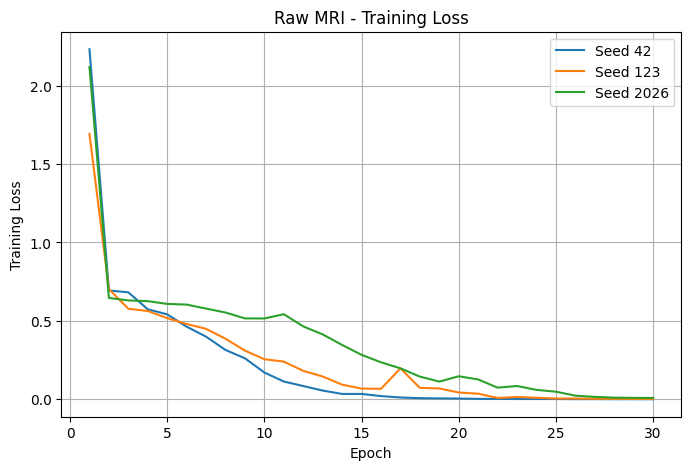

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for result in raw_results:
    seed = result["seed"]
    loss = result["history"]["loss"]

    epochs = range(1, len(loss) + 1)

    plt.plot(
        epochs,
        loss,
        label=f"Seed {seed}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Raw MRI - Training Loss")
plt.legend()
plt.grid(True)
plt.show()

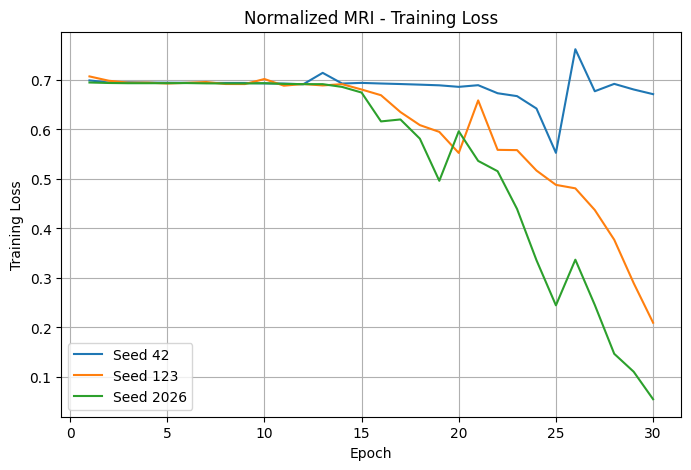

In [26]:
plt.figure(figsize=(8, 5))

for result in raw_results_norm:
    seed = result["seed"]
    loss = result["history"]["loss"]

    epochs = range(1, len(loss) + 1)

    plt.plot(
        epochs,
        loss,
        label=f"Seed {seed}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Normalized MRI - Training Loss")
plt.legend()
plt.grid(True)
plt.show()

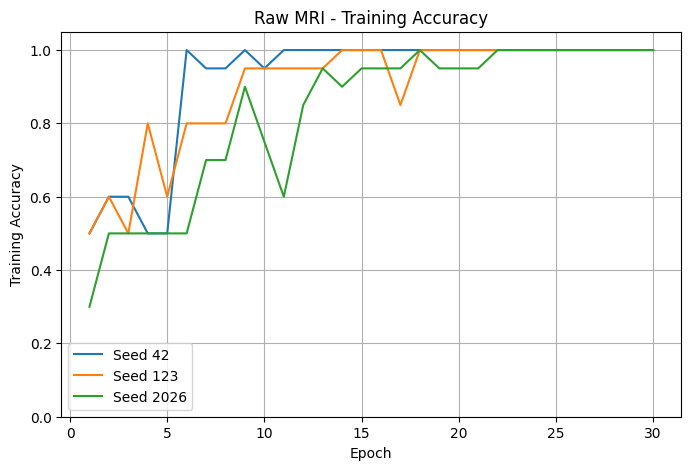

In [27]:
plt.figure(figsize=(8, 5))

for result in raw_results:
    seed = result["seed"]
    accuracy = result["history"]["accuracy"]

    epochs = range(1, len(accuracy) + 1)

    plt.plot(
        epochs,
        accuracy,
        label=f"Seed {seed}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Raw MRI - Training Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

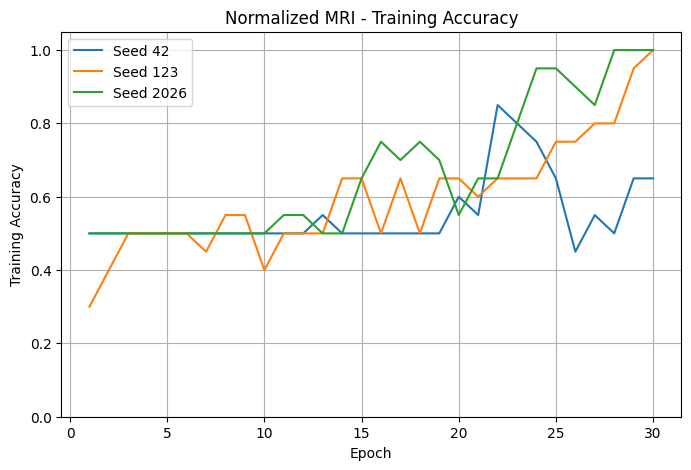

In [28]:
plt.figure(figsize=(8, 5))

for result in raw_results_norm:
    seed = result["seed"]
    accuracy = result["history"]["accuracy"]

    epochs = range(1, len(accuracy) + 1)

    plt.plot(
        epochs,
        accuracy,
        label=f"Seed {seed}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Normalized MRI - Training Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

## 5 Evaluataion

###  5.1 Metrics

Model performance was evaluated on the held-out test set using four metrics:

- **Accuracy**: the proportion of correctly classified subjects.
- **F1-score**: the harmonic mean of precision and recall for the patient class.
- **AUROC**: measures how well the model ranks patient subjects above health subjects across decision thresholds.
- **Confusion matrix**: shows the number of correct and incorrect predictions for both classes.

Because the test set contains only 10 subjects, each individual prediction changes the accuracy by 10 percentage points. Therefore, results are interpreted together with F1-score, AUROC, confusion matrices, and variability across random seeds.






|Condition|	Seed|	Accuracy|	F1-score|	AUROC|
|--|--|--|--|--|
|Raw|42|	0.800|	0.800	|0.800|
|Raw	|123	|0.800	|0.750	|0.680|
|Raw|	2026|	0.600|	0.333	|0.240|
|Normalized	|42	|0.600|	0.333	|0.720|
|Normalized|123|0.600	|0.500|0.880|
|Normalized|2026|	**0.900**|	**0.909**|	**0.960**|



In [29]:
rows = []

# Raw results
for result in raw_results:
    rows.append({
        "Condition": "Raw",
        "Seed": result["seed"],
        "Accuracy": result["accuracy"],
        "F1-score": result["f1"],
        "AUROC": result["auroc"]
    })

# Normalized results
for result in raw_results_norm:
    rows.append({
        "Condition": "Normalized",
        "Seed": result["seed"],
        "Accuracy": result["accuracy"],
        "F1-score": result["f1"],
        "AUROC": result["auroc"]
    })

results_df = pd.DataFrame(rows)

results_df.style.format({
    "Accuracy": "{:.3f}",
    "F1-score": "{:.3f}",
    "AUROC": "{:.3f}"
})


,Condition,Seed,Accuracy,F1-score,AUROC
0,Raw,42,0.800,0.800,0.800
1,Raw,123,0.800,0.750,0.680
2,Raw,2026,0.600,0.333,0.240
3,Normalized,42,0.600,0.333,0.720
4,Normalized,123,0.600,0.500,0.880
5,Normalized,2026,0.900,0.909,0.960


In [30]:
summary_table = pd.DataFrame({
    "Condition": ["Raw", "Normalized"],

    "Accuracy": [
        f"{results_df[results_df['Condition']=='Raw']['Accuracy'].mean():.3f} ± "
        f"{results_df[results_df['Condition']=='Raw']['Accuracy'].std():.3f}",

        f"{results_df[results_df['Condition']=='Normalized']['Accuracy'].mean():.3f} ± "
        f"{results_df[results_df['Condition']=='Normalized']['Accuracy'].std():.3f}"
    ],

    "F1-score": [
        f"{results_df[results_df['Condition']=='Raw']['F1-score'].mean():.3f} ± "
        f"{results_df[results_df['Condition']=='Raw']['F1-score'].std():.3f}",

        f"{results_df[results_df['Condition']=='Normalized']['F1-score'].mean():.3f} ± "
        f"{results_df[results_df['Condition']=='Normalized']['F1-score'].std():.3f}"
    ],

    "AUROC": [
        f"{results_df[results_df['Condition']=='Raw']['AUROC'].mean():.3f} ± "
        f"{results_df[results_df['Condition']=='Raw']['AUROC'].std():.3f}",

        f"{results_df[results_df['Condition']=='Normalized']['AUROC'].mean():.3f} ± "
        f"{results_df[results_df['Condition']=='Normalized']['AUROC'].std():.3f}"
    ]
})

summary_table


,Condition,Accuracy,F1-score,AUROC
0,Raw,0.733 ± 0.115,0.628 ± 0.256,0.573 ± 0.295
1,Normalized,0.700 ± 0.173,0.581 ± 0.296,0.853 ± 0.122


## 6. Conclusion

This project investigated 3D CNN classification of health and patient T1 MRI volumes using both raw and per-volume median-normalized intensities.

Exploratory analysis showed that the raw dataset contained a strong global intensity difference between the two classes. A simple subject-level intensity threshold was already highly predictive, indicating that absolute intensity scale could act as a shortcut feature.

To reduce this effect, each MRI volume was normalized by the median intensity of its nonzero brain voxels. The same CNN architecture and training hyperparameters were then applied to both raw and normalized data so that preprocessing was the primary experimental difference.

The results showed that model performance varied across random seeds, particularly for the normalized data. This suggests that the small training set of only 20 subjects makes optimization and generalization unstable. In several runs, the network achieved very high training accuracy while test performance remained lower, which is consistent with overfitting.

Overall, the experiment demonstrates that preprocessing can strongly influence CNN behavior in small medical imaging datasets. High classification performance on raw images should therefore be interpreted cautiously when global intensity differences may provide an unintended shortcut. The normalized experiment provides a more conservative test of whether the CNN can learn discriminative spatial information beyond global intensity scale.

## Reference


https://usmanr149.github.io/urmlblog/cs231n%20assignments/2020/03/29/FC-NN.html


https://developer.nvidia.com/discover/convolution

Wen, Junhao, et al. "Convolutional neural networks for classification of Alzheimer's disease: Overview and reproducible evaluation." Medical image analysis 63 (2020): 101694

